# Estados mais ricos possuem melhores oportunidades para profissionais de dados?

**Objetivo:** Cruzar as edições 2023 e 2024 da pesquisa *State of Data Brazil* (Data Hackers + Bain) com um indicador externo de riqueza por estado (PIB per capita, raspado da Wikipédia) para investigar se estados mais ricos oferecem melhores salários e mais oportunidades para profissionais de dados.

**Estrutura deste notebook:**
1. Setup e bibliotecas
2. Carregamento da base State of Data Brazil 2024
3. Web scraping do PIB per capita por estado
4. Padronização (chave de junção: UF)
5. Integração das bases (2024 + 2023)
6. Análise comparativa (correlações e métricas avançadas)
7. Narrativa visual (sequência de 7 gráficos)
8. Conclusão
9. Gerar relatório em PDF


## 1. Setup e bibliotecas

In [329]:
%pip install -q --upgrade beautifulsoup4 lxml plotly kaggle

import re
import json
import requests
import numpy
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from bs4 import BeautifulSoup
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)


You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


## 2. Carregamento da base State of Data Brazil (2024)

### 2.1 Baixar do Kaggle (ambiente local)

**Opção A — API do Kaggle (recomendada):**
1. No Kaggle, vá em *Settings > API > Create New Token*. Vai aparecer um token no formato `KGAT_...`.
2. **No terminal do seu computador (fora do notebook)**, salve esse token onde o pacote `kaggle` consegue ler, substituindo `SEU_TOKEN_AQUI` pelo token gerado:

   - **Mac/Linux:**
     ```bash
     mkdir -p ~/.kaggle
     echo "SEU_TOKEN_AQUI" > ~/.kaggle/access_token
     chmod 600 ~/.kaggle/access_token
     ```
   - **Windows (PowerShell):**
     ```powershell
     mkdir $env:USERPROFILE\.kaggle -Force
     "SEU_TOKEN_AQUI" | Out-File -FilePath "$env:USERPROFILE\.kaggle\access_token" -Encoding ascii -NoNewline
     ```
3. Feito isso, a célula de código abaixo já baixa o dataset sozinha.

> ⚠️ Trate esse token como uma senha: não cole em prints públicos nem em repositórios.

**Opção B — Download manual:** baixe o CSV direto da página do dataset no Kaggle e coloque o arquivo na mesma pasta deste notebook. Depois pule a célula abaixo e ajuste o caminho na célula seguinte (2.2).

In [330]:
# Opção A — API do Kaggle (rode só depois de configurar o access_token, conforme célula acima)
!kaggle datasets download -d datahackers/state-of-data-brazil-20242025


/Users/teuzin/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
Traceback (most recent call last):
  File "/Users/teuzin/Library/Python/3.9/bin/kaggle", line 8, in <module>
    sys.exit(main())
  File "/Users/teuzin/Library/Python/3.9/lib/python/site-packages/kaggle/cli.py", line 68, in main
    out = args.func(**command_args)
  File "/Users/teuzin/Library/Python/3.9/lib/python/site-packages/kaggle/api/kaggle_api_extended.py", line 1741, in dataset_download_cli
    with self.build_kaggle_client() as kaggle:
  File "/Users/teuzin/Library/Python/3.9/lib/python/site-packages/kaggle/api/kaggle_api_extended.py", line 688, in build_kaggle_client
    username=self.config_values['username'],
KeyError: 'username'


In [331]:
import zipfile

# Substitua pelo nome EXATO do arquivo que você baixou
arquivo_zip = "state-of-data-brazil-20242025.zip"
pasta_destino = "state-of-data-brazil-20242025"

with zipfile.ZipFile(arquivo_zip, 'r') as zip_ref:
    zip_ref.extractall(pasta_destino)

print("✅ Arquivos descompactados com sucesso!")


✅ Arquivos descompactados com sucesso!


In [332]:
# 2.2 Localizar o CSV dentro da pasta baixada
import glob
csv_candidatos = glob.glob("state-of-data-brazil-20242025/**/*.csv", recursive=True)
print(csv_candidatos)

# Ajuste o índice conforme o resultado acima
caminho_csv = csv_candidatos[0]


['state-of-data-brazil-20242025/Final Dataset - State of Data 2024 - Kaggle - df_survey_2024.csv']


In [333]:
# 2.3 Carregar o dataset
df = pd.read_csv(caminho_csv)
print("Linhas:", df.shape[0], "| Colunas:", df.shape[1])
df.head()


Linhas: 5217 | Colunas: 403


,0.a_token,0.d_data/hora_envio,1.a_idade,1.a.1_faixa_idade,1.b_genero,1.c_cor/raca/etnia,1.d_pcd,1.e_experiencia_profissional_prejudicada,1.e.1_Não acredito que minha experiência profissional seja afetada,"1.e.2_Sim, devido a minha Cor/Raça/Etnia","1.e.3_Sim, devido a minha identidade de gênero","1.e.4_Sim, devido ao fato de ser PCD",1.i.1_uf_onde_mora,1.f.1_Quantidade de oportunidades de emprego/vagas recebidas,1.f.2_Senioridade das vagas recebidas em relação à sua experiência,1.f.3_Aprovação em processos seletivos/entrevistas,1.f.4_Oportunidades de progressão de carreira,1.f.5_Velocidade de progressão de carreira,1.f.6_Nível de cobrança no trabalho/Stress no trabalho,1.f.7_Atenção dada pelas pessoas diante das minhas opiniões e ideias,"1.f.8_Relação com outras pessoas da empresa, em momentos de trabalho","1.f.9_Relação com outras pessoas da empresa, em momentos de integração e outros momentos fora do trabalho",1.i.2_regiao_onde_mora,1.f_aspectos_prejudicados,1.k.1_uf_de_origem,1.k.2_regiao_de_origem,1.g_vive_no_brasil,1.h_pais_onde_mora,1.i_estado_onde_mora,1.j_vive_no_estado_de_formacao,1.k_estado_de_origem,1.l_nivel_de_ensino,1.m_área_de_formação,2.a_situação_de_trabalho,2.b_setor,2.c_numero_de_funcionarios,2.d_atua_como_gestor,2.e_cargo_como_gestor,2.f_cargo_atual,2.g_nivel,2.h_faixa_salarial,2.i_tempo_de_experiencia_em_dados,2.j_tempo_de_experiencia_em_ti,2.k_satisfeito_atualmente,2.l.1_Remuneração/Salário,2.l.2_Benefícios,2.l.3_Propósito do trabalho e da empresa,2.l.4_Flexibilidade de trabalho remoto,2.l.5_Ambiente e clima de trabalho,2.l.6_Oportunidade de aprendizado e trabalhar com referências,...,"8.a.3_Sou responsável por entrar em contato com os times de negócio para definição do problema, identificar a solução e apresentação de resultados.",8.a.4_Desenvolvo modelos de Machine Learning com o objetivo de colocar em produção em sistemas (produtos de dados).,"8.a.5_Sou responsável por colocar modelos em produção, criar os pipelines de dados, APIs de consumo e monitoramento.","8.a.6_Cuido da manutenção de modelos de Machine Learning já em produção, atuando no monitoramento, ajustes e refatoração quando necessário.","8.a.7_Realizo construções de dashboards em ferramentas de BI como PowerBI, Tableau, Looker, Qlik, etc","8.a.8_Utilizo ferramentas avançadas de estatística como SAS, SPSS, Stata etc, para realizar análises.","8.a.9_Crio e dou manutenção em ETLs, DAGs e automações de pipelines de dados.",8.a.10_Crio e gerencio soluções de Feature Store e cultura de MLOps.,"8.a.11_Sou responsável por criar e manter a infra que meus modelos e soluções rodam (clusters, servidores, API, containers, etc.)",8.a.12_Treino e aplico LLM's para solucionar problemas de negócio.,8.b_tecnicas_e_metodos_ds,"8.b.1_Utilizo modelos de regressão (linear, logística, GLM).",8.b.2_Utilizo redes neurais ou modelos baseados em árvore para criar modelos de classificação.,8.b.3_Desenvolvo sistemas de recomendação (RecSys).,8.b.4_Utilizo métodos estatísticos Bayesianos para analisar dados.,8.b.5_Utilizo técnicas de NLP (Natural Language Processing) para análisar dados não-estruturados.,"8.b.6_Utilizo métodos estatísticos clássicos (Testes de hipótese, análise multivariada, sobrevivência, dados longitudinais, inferência estatistica) para analisar dados.",8.b.7_Utilizo cadeias de Markov ou HMM\s para realizar análises de dados.,"8.b.8_Desenvolvo técnicas de Clusterização (K-means, Spectral, DBScan etc).",8.b.9_Realizo previsões através de modelos de Séries Temporais (Time Series).,8.b.10_Utilizo modelos de Reinforcement Learning (aprendizado por reforço).,8.b.11_Utilizo modelos de Machine Learning para detecção de fraude.,8.b.12_Utilizo métodos de Visão Computacional.,8.b.13_Utilizo modelos de Detecção de Churn.,8.b.14_Utilizo LLM's para solucionar problemas de negócio.,8.c_tecnologias_ds,"8.c.1_Ferramentas de BI (PowerBI, Looker, Tableau, Qlik etc).","8.c.2_Planilhas (Excel, Google Sheets etc).","8.c.3_Ambientes de desenvolvimento local (R-studio, Jupy

### 2.4 Encontrar as colunas relevantes

A pesquisa tem mais de 400 colunas com nomes longos (tipo perguntas). Em vez de adivinhar o nome exato, vamos buscar por palavras-chave.

In [334]:
def localizar_colunas(df, palavras_chave):
    encontradas = []
    for col in df.columns:
        for kw in palavras_chave:
            if kw.lower() in col.lower():
                encontradas.append(col)
                break
    return encontradas

colunas_estado  = localizar_colunas(df, ["estado", "uf", "onde você mora", "localiza"])
colunas_salario = localizar_colunas(df, ["salário", "faixa salarial", "remuneração"])
colunas_cargo   = localizar_colunas(df, ["cargo", "posição que ocupa", "função"])
colunas_senior  = localizar_colunas(df, ["senioridade", "nível"])

print("Estado:", colunas_estado)
print("Salário:", colunas_salario)
print("Cargo:", colunas_cargo)
print("Senioridade:", colunas_senior)


Estado: ['1.i.1_uf_onde_mora', '1.k.1_uf_de_origem', '1.i_estado_onde_mora', '1.j_vive_no_estado_de_formacao', '1.k_estado_de_origem']
Salário: ['2.l.1_Remuneração/Salário', '2.o.1_Remuneração/Salário']
Cargo: ['2.e_cargo_como_gestor', '2.f_cargo_atual', '3.b_cargos_no_time_de_dados_da_empresa']
Senioridade: ['1.f.2_Senioridade das vagas recebidas em relação à sua experiência', '1.f.6_Nível de cobrança no trabalho/Stress no trabalho']


In [335]:
# Checagem: confirmar que essas colunas de "salário" não eram apenas 0/1 (fatores de satisfação)
print(sorted(df[colunas_salario[0]].dropna().unique()))
print(sorted(df[colunas_salario[1]].dropna().unique()))


[np.float64(0.0), np.float64(1.0)]
[np.float64(0.0), np.float64(1.0)]


In [336]:
# Inspeção de todas as colunas da seção 2 (carreira) — foi assim que achamos a coluna certa de salário
colunas_secao2 = [c for c in df.columns if c.startswith("2.")]
for c in colunas_secao2:
    print(c)


2.a_situação_de_trabalho
2.b_setor
2.c_numero_de_funcionarios
2.d_atua_como_gestor
2.e_cargo_como_gestor
2.f_cargo_atual
2.g_nivel
2.h_faixa_salarial
2.i_tempo_de_experiencia_em_dados
2.j_tempo_de_experiencia_em_ti
2.k_satisfeito_atualmente
2.l.1_Remuneração/Salário
2.l.2_Benefícios
2.l.3_Propósito do trabalho e da empresa
2.l.4_Flexibilidade de trabalho remoto
2.l.5_Ambiente e clima de trabalho
2.l.6_Oportunidade de aprendizado e trabalhar com referências
2.l.7_Oportunidades de crescimento
2.l.8_Maturidade da empresa em termos de tecnologia e dados
2.l.9_Relação com os gestores e líderes
2.l.10_Reputação que a empresa tem no mercado
2.l.11_Gostaria de trabalhar em outra área
2.l_motivo_insatisfacao
2.m_participou_de_entrevistas_ultimos_6m
2.n_planos_de_mudar_de_emprego_6m
2.o_criterios_para_escolha_de_emprego
2.o.1_Remuneração/Salário
2.o.2_Benefícios
2.o.3_Propósito do trabalho e da empresa
2.o.4_Flexibilidade de trabalho remoto
2.o.5_Ambiente e clima de trabalho
2.o.6_Oportunidade d

In [337]:
# Colunas confirmadas após a inspeção acima
col_estado  = "1.i.1_uf_onde_mora"
col_cargo   = "2.f_cargo_atual"
col_salario = "2.h_faixa_salarial"

df[[col_estado, col_salario, col_cargo]].head(10)


,1.i.1_uf_onde_mora,2.h_faixa_salarial,2.f_cargo_atual
0,RS,de R$ 1.001/mês a R$ 2.000/mês,Analista de Dados/Data Analyst
1,SC,Menos de R$ 1.000/mês,Analista de BI/BI Analyst
2,SP,de R$ 1.001/mês a R$ 2.000/mês,Outra Opção
3,SP,de R$ 1.001/mês a R$ 2.000/mês,Analista de Dados/Data Analyst
4,SP,de R$ 1.001/mês a R$ 2.000/mês,Desenvolvedor/ Engenheiro de Software/ Analist...
5,DF,NaN,NaN
6,SP,de R$ 6.001/mês a R$ 8.000/mês,Analista de BI/BI Analyst
7,SP,de R$ 1.001/mês a R$ 2.000/mês,Outra Opção
8,MA,Menos de R$ 1.000/mês,Outra Opção
9,SP,de R$ 3.001/mês a R$ 4.000/mês,Desenvolvedor/ Engenheiro de Software/ Analist...


## 3. Web Scraping — PIB per capita por estado

Fonte: tabela da Wikipédia *"Lista de unidades federativas do Brasil por PIB per capita"*.

In [338]:
url = "https://pt.wikipedia.org/wiki/Lista_de_unidades_federativas_do_Brasil_por_PIB_per_capita"
headers = {"User-Agent": "Mozilla/5.0 (trabalho academico de ciencia de dados)"}

resp = requests.get(url, headers=headers, timeout=20)
resp.raise_for_status()

soup = BeautifulSoup(resp.text, "lxml")
tabela = soup.find("table", {"class": "wikitable"})

from io import StringIO
pib_raw = pd.read_html(StringIO(str(tabela)))[0]
pib_raw.head(15)


Posição                      Unidade federativa  \
   Em 2023[1] Comparada a 2022[2]  Unidade federativa   
0           1                 (0)    Distrito Federal   
1           2                 (1)           São Paulo   
2           3                 (1)         Mato Grosso   
3           4                 (2)      Rio de Janeiro   
4           5                 (0)      Santa Catarina   
5           6                 (0)  Mato Grosso do Sul   
6           7                 (0)   Rio Grande do Sul   
7           8                 (0)              Paraná   
8           9                 (0)      Espírito Santo   
9          10                 (2)            Rondônia   
10         11                 (1)               Goiás   
11         12                 (1)        Minas Gerais   
12         13                 (0)           Tocantins   
13         14                 (0)            Amazonas   
14         15                 (0)             Roraima   

   PIB per capita em R$ (2023) Razão UF / Brasil  
   PIB per capita em R$ (2023) Razão UF / Brasil  
0                   129.790,44               241  
1                    77.566,27               144  
2                    74.620,05               138  
3                    73.052,55               136  
4                    67.459,74               125  
5                    66.884,75               124  
6                    59.736,20               111  
7                    58.624,33               109  
8                    54.732,78               102  
9                    48.353,38                 9  
10                   47.721,56                89  
11                   47.321,23                88  
12                   42.553,36                79  
13                   41.047,91                76  
14                   39.460,54                73

In [339]:
# Inspecione os nomes de coluna retornados
print(pib_raw.columns.tolist())


[('Posição', 'Em 2023[1]'), ('Posição', 'Comparada a 2022[2]'), ('Unidade federativa', 'Unidade federativa'), ('PIB per capita em R$ (2023)', 'PIB per capita em R$ (2023)'), ('Razão UF / Brasil', 'Razão UF / Brasil')]


In [340]:
# Achatar cabeçalho duplo da Wikipédia
pib_raw.columns = [c[0] if isinstance(c, tuple) else c for c in pib_raw.columns]

pib = pib_raw.rename(columns={
    "Unidade federativa": "estado",
    "PIB per capita em R$ (2023)": "pib_per_capita",
})[["estado", "pib_per_capita"]].copy()

pib["estado"] = pib["estado"].str.replace(r"\[.*?\]", "", regex=True).str.strip()
pib["pib_per_capita"] = (
    pib["pib_per_capita"].astype(str)
    .str.replace(r"\[.*?\]", "", regex=True)
    .str.replace(r"[^\d,]", "", regex=True)
    .str.replace(",", ".", regex=False)
)
pib["pib_per_capita"] = pd.to_numeric(pib["pib_per_capita"], errors="coerce")
pib = pib.dropna(subset=["pib_per_capita"]).reset_index(drop=True)
pib = pib[pib["estado"] != "Brasil"].reset_index(drop=True)
pib.head(30)


,estado,pib_per_capita
0,Distrito Federal,129790.44
1,São Paulo,77566.27
2,Mato Grosso,74620.05
3,Rio de Janeiro,73052.55
4,Santa Catarina,67459.74
5,Mato Grosso do Sul,66884.75
6,Rio Grande do Sul,59736.20
7,Paraná,58624.33
8,Espírito Santo,54732.78
9,Rondônia,48353.38


In [341]:
# Salvar o dataset externo coletado (evidência do scraping para o relatório)
pib.to_csv("pib_per_capita_estados.csv", index=False)
pib.shape


(27, 2)

### 3.2 Web Scraping — População por estado

Necessário para calcular a **densidade de respondentes** (Seção 6.2). Fonte: tabela da Wikipédia *"Lista de unidades federativas do Brasil por população"* (dados IBGE).

In [342]:
url_populacao = "https://pt.wikipedia.org/wiki/Lista_de_unidades_federativas_do_Brasil_por_popula%C3%A7%C3%A3o"

resp_pop = requests.get(url_populacao, headers=headers, timeout=20)
resp_pop.raise_for_status()

soup_pop = BeautifulSoup(resp_pop.text, "lxml")
tabela_pop = soup_pop.find("table", {"class": "wikitable"})

pop_raw = pd.read_html(StringIO(str(tabela_pop)))[0]
pop_raw.head(30)


Unidade federativa População[3][4]              Variação (2010-2022)[3]  \
     Unidade federativa     2025 (est.)         2022                       %   
0             São Paulo      46 081 801   44 411 238                   7,63%   
1          Minas Gerais      21 393 441   20 539 989                   4,81%   
2        Rio de Janeiro      17 223 547   16 055 174                   0,41%   
3                 Bahia      14 870 907   14 141 626                   0,89%   
4                Paraná      11 890 517   11 444 380                   9,57%   
5     Rio Grande do Sul      11 233 263   10 882 965                   1,77%   
6            Pernambuco       9 562 007    9 058 931                   2,98%   
7                 Ceará       9 268 836    8 794 957                   4,05%   
8                  Pará       8 711 196    8 120 131                   7,11%   
9        Santa Catarina       8 187 029    7 610 361                  21,80%   
10                Goiás       7 423 629    7 056 495                  17,53%   
11             Maranhão       7 018 211    6 776 699                   3,07%   
12             Amazonas       4 321 616    3 941 613                  13,14%   
13              Paraíba       4 164 468    3 974 687                   5,53%   
14       Espírito Santo       4 126 854    3 833 712                   9,07%   
15          Mato Grosso       3 893 659    3 658 649                  20,54%   
16  Rio Grande do Norte       3 455 236    3 302 729                   4,25%   
17                Piauí       3 384 547    3 271 199                   4,90%   
18              Alagoas       3 220 848    3 127 683                   0,23%   
19     Distrito Federal       2 996 899    2 817 381                   9,62%   
20   Mato Grosso do Sul       2 924 631    2 757 013                  12,58%   
21              Sergipe       2 299 425    2 210 004                   6,87%   
22             Rondônia       1 751 950    1 581 196                   1,20%   
23            Tocantins       1 586 859    1 511 460                   9,25%   
24                 Acre         884 372      830 018                  13,15%   
25                Amapá         806 517      733 759                   9,59%   
26              Roraima         738 772      636 707                  41,34%   
27                Total     213 421 037  203 080 756                   6,46%   

               % do total (2025)[4]   País comparável (habitantes)[5][a]  
          Abs. % do total (2025)[4]   País comparável (habitantes)[5][a]  
0    3 149 039               21,59%               Argentina (45 851 378)  
1      942 659               10,02%                   Chade (21 003 705)  
2       65 245                8,07%                Zimbabwe (16 950 795)  
3      124 720                6,97%                   Benim (14 814 460)  
4      999 854                5,57%                   Haiti (11 906 095)  
5      189 036                5,26%  Emirados Árabes Unidos (11 346 000)  
6      262 483                4,48%                   Israel (9 517 181)  
7      342 576                4,34%                  Áustria (9 113 574)  
8      539 080                4,08%               Serra Leoa (8 819 794)  
9    1 361 925                3,84%                     Laos (7 873 046)  
10   1 052 707                3,48%                    Líbia (7 458 555)  
11     201 910                3,29%                 Paraguai (7 013 078)  
12     457 628                2,02%                   Panamá (4 571 189)  
13     208 159                1,95%                  Croácia (3 848 160)  
14     318 760                1,93%                  Croácia (3 848 160)  
15     623 527                1,82%                  Croácia (3 848 160)  
16     134 702                1,62%                 Mongólia (3 517 100)  
17     152 839                1,59%                  Uruguai (3 384 688)  
18       7 189                1,51%     Bósnia e Herzegovina (3 140 095)  
19     247 221               

In [343]:
# Achatar cabeçalho duplo, deduplicando partes repetidas (ex: "Unidade federativa"/"Unidade federativa" -> só uma vez)
def achatar_coluna(c):
    if isinstance(c, tuple):
        partes = [str(x) for x in c if "Unnamed" not in str(x)]
        unicas = []
        for p in partes:
            if not unicas or unicas[-1] != p:
                unicas.append(p)
        return "_".join(unicas)
    return str(c)

pop_raw.columns = [achatar_coluna(c) for c in pop_raw.columns]
print(pop_raw.columns.tolist())

['Unidade federativa', 'População[3][4]_2025 (est.)', 'População[3][4]_2022', 'Variação (2010-2022)[3]_%', 'Variação (2010-2022)[3]_Abs.', '% do total (2025)[4]', 'País comparável (habitantes)[5][a]']


In [344]:
# Seleção das colunas certas:
# - "Unidade federativa": nome do estado
# - Dentro do grupo "População", usamos a coluna do censo 2022 (dado real, mais alinhado
#   temporalmente com o PIB ano-base 2023 e a pesquisa 2023/2024) em vez da projeção 2025.
col_estado_pop = [c for c in pop_raw.columns if "unidade federativa" in c.lower()][0]
col_pop_valor  = [c for c in pop_raw.columns if c.lower().startswith("população") and "2022" in c][0]

print(f"Coluna de estado: {col_estado_pop}")
print(f"Coluna de população: {col_pop_valor}")

populacao = pop_raw[[col_estado_pop, col_pop_valor]].rename(
    columns={col_estado_pop: "estado", col_pop_valor: "populacao"}
)

populacao["estado"] = populacao["estado"].str.replace(r"\[.*?\]", "", regex=True).str.strip()
populacao["populacao"] = (
    populacao["populacao"].astype(str)
    .str.replace(r"\[.*?\]", "", regex=True)
    .str.replace(r"[^\d]", "", regex=True)
)
populacao["populacao"] = pd.to_numeric(populacao["populacao"], errors="coerce")
populacao = populacao.dropna(subset=["populacao"]).reset_index(drop=True)
populacao = populacao[~populacao["estado"].isin(["Brasil", "Total"])].reset_index(drop=True)

print(f"Linhas capturadas: {len(populacao)}  (esperado: 27 estados)")
populacao.head(30)

Coluna de estado: Unidade federativa
Coluna de população: População[3][4]_2022
Linhas capturadas: 27  (esperado: 27 estados)


,estado,populacao
0,São Paulo,44411238
1,Minas Gerais,20539989
2,Rio de Janeiro,16055174
3,Bahia,14141626
4,Paraná,11444380
5,Rio Grande do Sul,10882965
6,Pernambuco,9058931
7,Ceará,8794957
8,Pará,8120131
9,Santa Catarina,7610361


In [345]:
populacao.to_csv("populacao_estados.csv", index=False)
populacao.shape


(27, 2)

## 4. Padronização — chave de junção (UF)

A pesquisa pode trazer o estado por extenso ou por sigla. Vamos garantir que as duas bases falem a mesma língua usando a sigla (UF) como chave.

In [346]:
mapa_uf = {
    "Acre": "AC", "Alagoas": "AL", "Amapá": "AP", "Amazonas": "AM", "Bahia": "BA",
    "Ceará": "CE", "Distrito Federal": "DF", "Espírito Santo": "ES", "Goiás": "GO",
    "Maranhão": "MA", "Mato Grosso": "MT", "Mato Grosso do Sul": "MS", "Minas Gerais": "MG",
    "Pará": "PA", "Paraíba": "PB", "Paraná": "PR", "Pernambuco": "PE", "Piauí": "PI",
    "Rio de Janeiro": "RJ", "Rio Grande do Norte": "RN", "Rio Grande do Sul": "RS",
    "Rondônia": "RO", "Roraima": "RR", "Santa Catarina": "SC", "São Paulo": "SP",
    "Sergipe": "SE", "Tocantins": "TO",
}
mapa_regiao = {
    "AC": "Norte", "AP": "Norte", "AM": "Norte", "PA": "Norte", "RO": "Norte", "RR": "Norte", "TO": "Norte",
    "AL": "Nordeste", "BA": "Nordeste", "CE": "Nordeste", "MA": "Nordeste", "PB": "Nordeste",
    "PE": "Nordeste", "PI": "Nordeste", "RN": "Nordeste", "SE": "Nordeste",
    "DF": "Centro-Oeste", "GO": "Centro-Oeste", "MT": "Centro-Oeste", "MS": "Centro-Oeste",
    "ES": "Sudeste", "MG": "Sudeste", "RJ": "Sudeste", "SP": "Sudeste",
    "PR": "Sul", "RS": "Sul", "SC": "Sul",
}

pib["uf"] = pib["estado"].map(mapa_uf)
pib["regiao"] = pib["uf"].map(mapa_regiao)

if df[col_estado].dropna().astype(str).str.len().median() <= 3:
    df["uf"] = df[col_estado].astype(str).str.upper().str.strip()
else:
    df["uf"] = df[col_estado].map(mapa_uf)

df["uf"].value_counts(dropna=False).head(30)


uf
SP     2064
MG      580
PR      415
RJ      397
RS      369
SC      247
DF      186
NAN     142
CE      128
PE      120
BA       99
ES       91
GO       72
PB       53
MT       44
MS       30
RN       30
MA       28
AM       23
AL       23
SE       21
PA       18
PI       14
RO       13
TO        6
AP        4
Name: count, dtype: int64

### 4.1 Incorporar a população (mapear UF e juntar ao PIB)

In [347]:
populacao["uf"] = populacao["estado"].map(mapa_uf)
populacao = populacao.dropna(subset=["uf"]).reset_index(drop=True)  # remove linhas de região (Norte, Nordeste, etc.)

pib = pib.merge(populacao[["uf", "populacao"]], on="uf", how="left")
print(f"Estados com PIB e população mapeados: {pib['populacao'].notna().sum()} de {len(pib)}")
pib.head(30)


Estados com PIB e população mapeados: 27 de 27


,estado,pib_per_capita,uf,regiao,populacao
0,Distrito Federal,129790.44,DF,Centro-Oeste,2817381
1,São Paulo,77566.27,SP,Sudeste,44411238
2,Mato Grosso,74620.05,MT,Centro-Oeste,3658649
3,Rio de Janeiro,73052.55,RJ,Sudeste,16055174
4,Santa Catarina,67459.74,SC,Sul,7610361
5,Mato Grosso do Sul,66884.75,MS,Centro-Oeste,2757013
6,Rio Grande do Sul,59736.20,RS,Sul,10882965
7,Paraná,58624.33,PR,Sul,11444380
8,Espírito Santo,54732.78,ES,Sudeste,3833712
9,Rondônia,48353.38,RO,Norte,1581196


## 5. Integração das bases (2024 + 2023)

Primeiro integramos a edição 2024, depois repetimos o processo para 2023 e juntamos as duas — isso aumenta o número de observações por estado e permite testar se o padrão se mantém ao longo do tempo.

### 5.1 Integrar a edição 2024

In [348]:
def faixa_para_numero(faixa):
    """Extrai os números de uma faixa salarial tipo 'de R$ 4.001/mês a R$ 6.000/mês'
    e retorna o ponto médio. Ajuste a regex se o formato da sua versão do dataset for diferente."""
    if pd.isna(faixa):
        return numpy.nan
    numeros = re.findall(r"[\d\.]+", str(faixa))
    numeros = [float(n.replace(".", "")) for n in numeros if n.replace(".", "").isdigit()]
    if len(numeros) >= 2:
        return sum(numeros[:2]) / 2
    elif len(numeros) == 1:
        return numeros[0]
    return numpy.nan

df["salario_num"] = df[col_salario].apply(faixa_para_numero)
df[[col_salario, "salario_num"]].drop_duplicates().head(15)


,2.h_faixa_salarial,salario_num
0,de R$ 1.001/mês a R$ 2.000/mês,1500.5
1,Menos de R$ 1.000/mês,1000.0
5,NaN,NaN
6,de R$ 6.001/mês a R$ 8.000/mês,7000.5
9,de R$ 3.001/mês a R$ 4.000/mês,3500.5
11,de R$ 2.001/mês a R$ 3.000/mês,2500.5
14,de R$ 4.001/mês a R$ 6.000/mês,5000.5
73,de R$ 8.001/mês a R$ 12.000/mês,10000.5
118,de R$ 12.001/mês a R$ 16.000/mês,14000.5
212,de R$ 30.001/mês a R$ 40.000/mês,35000.5


In [349]:
agregado = (
    df.dropna(subset=["uf"])
    .groupby("uf")
    .agg(
        n_respondentes=("uf", "count"),
        salario_medio=("salario_num", "mean"),
        salario_mediano=("salario_num", "median"),
    )
    .reset_index()
)

base_final = agregado.merge(pib[["uf", "estado", "pib_per_capita", "regiao", "populacao"]], on="uf", how="inner")
base_final = base_final.sort_values("pib_per_capita", ascending=False).reset_index(drop=True)

# Métricas derivadas (4 e 5)
base_final["densidade_profissionais"] = base_final["n_respondentes"] / base_final["populacao"] * 100000
base_final["salario_relativo_pib"] = base_final["salario_medio"] / base_final["pib_per_capita"]

base_final


,uf,n_respondentes,salario_medio,salario_mediano,estado,pib_per_capita,regiao,populacao,densidade_profissionais,salario_relativo_pib
0,DF,186,11562.209877,10000.5,Distrito Federal,129790.44,Centro-Oeste,2817381,6.601876,0.089084
1,SP,2064,13387.073582,10000.5,São Paulo,77566.27,Sudeste,44411238,4.647472,0.172589
2,MT,44,7465.616279,5000.5,Mato Grosso,74620.05,Centro-Oeste,3658649,1.202630,0.100048
3,RJ,397,11633.834722,10000.5,Rio de Janeiro,73052.55,Sudeste,16055174,2.472723,0.159253
4,SC,247,10805.121849,10000.5,Santa Catarina,67459.74,Sul,7610361,3.245575,0.160171
5,MS,30,8533.833333,7000.5,Mato Grosso do Sul,66884.75,Centro-Oeste,2757013,1.088134,0.127590
6,RS,369,9587.149148,7000.5,Rio Grande do Sul,59736.20,Sul,10882965,3.390620,0.160491
7,PR,415,10836.348371,10000.5,Paraná,58624.33,Sul,11444380,3.626234,0.184844
8,ES,91,9750.500000,10000.5,Espírito Santo,54732.78,Sudeste,3833712,2.373679,0.178147
9,RO,13,9042.166667,5000.5,Rondônia,48353.38,Norte,1581196,0.822162,0.187002


In [350]:
base_final.to_csv("base_integrada_estado_data_pib.csv", index=False)


### 5.2 Baixar e carregar a edição 2023

In [351]:
# Usa a mesma autenticação já configurada (kaggle auth login)
!kaggle datasets download -d datahackers/state-of-data-brazil-2023


/Users/teuzin/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
Traceback (most recent call last):
  File "/Users/teuzin/Library/Python/3.9/bin/kaggle", line 8, in <module>
    sys.exit(main())
  File "/Users/teuzin/Library/Python/3.9/lib/python/site-packages/kaggle/cli.py", line 68, in main
    out = args.func(**command_args)
  File "/Users/teuzin/Library/Python/3.9/lib/python/site-packages/kaggle/api/kaggle_api_extended.py", line 1741, in dataset_download_cli
    with self.build_kaggle_client() as kaggle:
  File "/Users/teuzin/Library/Python/3.9/lib/python/site-packages/kaggle/api/kaggle_api_extended.py", line 688, in build_kaggle_client
    username=self.config_values['username'],
KeyError: 'username'


In [352]:
arquivo_zip_2023 = "state-of-data-brazil-2023.zip"
pasta_destino_2023 = "state-of-data-brazil-2023"

with zipfile.ZipFile(arquivo_zip_2023, 'r') as zip_ref:
    zip_ref.extractall(pasta_destino_2023)

print("✅ Arquivos de 2023 descompactados com sucesso!")


✅ Arquivos de 2023 descompactados com sucesso!


In [353]:
csv_candidatos_2023 = glob.glob("state-of-data-brazil-2023/**/*.csv", recursive=True)
print(csv_candidatos_2023)

# Ajuste o índice se vier mais de um arquivo na lista
caminho_csv_2023 = csv_candidatos_2023[0]
df23 = pd.read_csv(caminho_csv_2023)
print("Linhas:", df23.shape[0], "| Colunas:", df23.shape[1])


['state-of-data-brazil-2023/State_of_data_BR_2023_Kaggle - df_survey_2023.csv']
Linhas: 5293 | Colunas: 399


In [354]:
# Reaproveita a função já criada na Seção 2 para achar as colunas certas em 2023
colunas_estado_23  = localizar_colunas(df23, ["estado", "uf", "onde você mora", "localiza"])
colunas_salario_23 = localizar_colunas(df23, ["faixa salarial", "salário", "remuneração"])
colunas_cargo_23   = localizar_colunas(df23, ["cargo atual", "cargo", "posição que ocupa"])

print("Estado:", colunas_estado_23)
print("Salário:", colunas_salario_23)
print("Cargo:", colunas_cargo_23)


Estado: ["('P1_i ', 'Estado onde mora')", "('P1_i_1 ', 'uf onde mora')", "('P1_j ', 'Mudou de Estado?')"]
Salário: ["('P2_h ', 'Faixa salarial')", "('P2_l_2 ', 'Salário atual não corresponde ao mercado')", "('P2_o_1 ', 'Remuneração/Salário')"]
Cargo: ["('P2_e ', 'Cargo como Gestor')", "('P2_f ', 'Cargo Atual')", "('P3_b ', 'Quais desses papéis/cargos fazem parte do time (ou chapter) de dados da sua empresa?')", "('P4_a ', 'Mesmo que esse não seja seu cargo formal, você considera que sua atuação no dia a dia, reflete alguma das opções listadas abaixo?')"]


In [355]:
# AJUSTE AQUI: confira os prints acima (o nome exato muda de ano pra ano) e ajuste se precisar
col_estado_23  = colunas_estado_23[1]   # ('P1_i_1 ', 'uf onde mora') — já vem como sigla
col_salario_23 = colunas_salario_23[0]  # ('P2_h ', 'Faixa salarial') — a faixa de verdade
col_cargo_23   = colunas_cargo_23[1]    # ('P2_f ', 'Cargo Atual') — preenchido por todo mundo

df23[[col_estado_23, col_salario_23, col_cargo_23]].head(10)


,"('P1_i_1 ', 'uf onde mora')","('P2_h ', 'Faixa salarial')","('P2_f ', 'Cargo Atual')"
0,MG,de R$ 12.001/mês a R$ 16.000/mês,Cientista de Dados/Data Scientist
1,ES,de R$ 6.001/mês a R$ 8.000/mês,Analista de BI/BI Analyst
2,SP,de R$ 6.001/mês a R$ 8.000/mês,Analista de Dados/Data Analyst
3,SP,NaN,NaN
4,MG,de R$ 4.001/mês a R$ 6.000/mês,Analista de Dados/Data Analyst
5,RJ,de R$ 8.001/mês a R$ 12.000/mês,Engenheiro de Dados/Arquiteto de Dados/Data En...
6,SP,de R$ 4.001/mês a R$ 6.000/mês,Analista de Negócios/Business Analyst
7,SP,de R$ 20.001/mês a R$ 25.000/mês,NaN
8,RJ,NaN,NaN
9,SP,NaN,NaN


### 5.3 Padronizar, agregar 2023 e juntar com 2024

In [356]:
if df23[col_estado_23].dropna().astype(str).str.len().median() <= 3:
    df23["uf"] = df23[col_estado_23].astype(str).str.upper().str.strip()
else:
    df23["uf"] = df23[col_estado_23].map(mapa_uf)

df23["salario_num"] = df23[col_salario_23].apply(faixa_para_numero)

agregado_2023 = (
    df23.dropna(subset=["uf"])
    .groupby("uf")
    .agg(
        n_respondentes=("uf", "count"),
        salario_medio=("salario_num", "mean"),
        salario_mediano=("salario_num", "median"),
    )
    .reset_index()
)
agregado_2023["ano"] = 2023

agregado_2024 = agregado.copy()
agregado_2024["ano"] = 2024

agregado_multi = pd.concat([agregado_2024, agregado_2023], ignore_index=True)
base_multi = agregado_multi.merge(pib[["uf", "estado", "pib_per_capita", "regiao", "populacao"]], on="uf", how="inner")
base_multi = base_multi.sort_values(["ano", "pib_per_capita"], ascending=[True, False]).reset_index(drop=True)

base_multi["densidade_profissionais"] = base_multi["n_respondentes"] / base_multi["populacao"] * 100000
base_multi["salario_relativo_pib"] = base_multi["salario_medio"] / base_multi["pib_per_capita"]

print(f"Total de observações (estado x ano): {len(base_multi)}  |  Antes (só 2024): {len(base_final)}")
base_multi.head(10)


Total de observações (estado x ano): 50  |  Antes (só 2024): 25


,uf,n_respondentes,salario_medio,salario_mediano,ano,estado,pib_per_capita,regiao,populacao,densidade_profissionais,salario_relativo_pib
0,DF,175,11947.868421,10000.5,2023,Distrito Federal,129790.44,Centro-Oeste,2817381,6.211442,0.092055
1,SP,2073,11634.017942,10000.5,2023,São Paulo,77566.27,Sudeste,44411238,4.667737,0.149988
2,MT,47,8102.772727,7000.5,2023,Mato Grosso,74620.05,Centro-Oeste,3658649,1.284627,0.108587
3,RJ,437,9679.790404,10000.5,2023,Rio de Janeiro,73052.55,Sudeste,16055174,2.721864,0.132504
4,SC,250,9891.529915,10000.5,2023,Santa Catarina,67459.74,Sul,7610361,3.284995,0.146629
5,MS,29,8778.277778,7000.5,2023,Mato Grosso do Sul,66884.75,Centro-Oeste,2757013,1.051863,0.131245
6,RS,291,9635.996183,7000.5,2023,Rio Grande do Sul,59736.20,Sul,10882965,2.673904,0.161309
7,PR,420,9135.119231,7000.5,2023,Paraná,58624.33,Sul,11444380,3.669924,0.155825
8,ES,106,9011.026316,7000.5,2023,Espírito Santo,54732.78,Sudeste,3833712,2.764944,0.164637
9,RO,7,9786.214286,7000.5,2023,Rondônia,48353.38,Norte,1581196,0.442703,0.202389


In [357]:
# Diagnóstico: quais UFs ficaram de fora do cruzamento na pesquisa de 2024?
ufs_agregado_2024 = set(agregado["uf"].unique())
ufs_pib = set(pib["uf"].dropna().unique())

print("UFs da pesquisa 2024 que NÃO bateram com o PIB/população:", ufs_agregado_2024 - ufs_pib)
print("UFs do PIB/população que NÃO bateram com a pesquisa 2024:", ufs_pib - ufs_agregado_2024)
print()
print("Total de UFs únicos em 'pib':", len(ufs_pib))
print("Valores nulos em pib['uf']:", pib['uf'].isna().sum())
print("Valores nulos em pib['populacao']:", pib['populacao'].isna().sum())

UFs da pesquisa 2024 que NÃO bateram com o PIB/população: {'NAN'}
UFs do PIB/população que NÃO bateram com a pesquisa 2024: {'RR', 'AC'}

Total de UFs únicos em 'pib': 27
Valores nulos em pib['uf']: 0
Valores nulos em pib['populacao']: 0


> **Nota sobre o PIB per capita:** usamos o mesmo valor (ano-base 2023, o mais recente disponível) para as duas edições da pesquisa. A posição relativa de riqueza entre os estados muda muito pouco de um ano pro outro, então essa simplificação é razoável — mas vale citar como limitação no relatório.

In [358]:
base_multi.to_csv("base_integrada_multi_ano.csv", index=False)


## 6. Análise comparativa

In [359]:
corr_salario, p_salario = stats.pearsonr(base_final["pib_per_capita"], base_final["salario_medio"])
corr_oport,  p_oport   = stats.pearsonr(base_final["pib_per_capita"], base_final["n_respondentes"])

print(f"Correlação PIB per capita x salário médio:        r = {corr_salario:.2f}  (p = {p_salario:.3f})")
print(f"Correlação PIB per capita x nº de respondentes:    r = {corr_oport:.2f}  (p = {p_oport:.3f})")


Correlação PIB per capita x salário médio:        r = 0.45  (p = 0.023)
Correlação PIB per capita x nº de respondentes:    r = 0.37  (p = 0.071)


**Como interpretar:**
- `r` próximo de **1** → relação positiva forte (estado mais rico = salário/oportunidade maior).
- `r` próximo de **0** → praticamente nenhuma relação linear.
- `p < 0.05` → a correlação observada provavelmente não é fruto do acaso (use isso com cautela: a amostra é só de ~25 estados).

Os testes abaixo aprofundam essa análise, testando a robustez do resultado.

### 6.1 Métricas avançadas

- **Spearman**: correlação baseada em ranking (posição relativa), não no valor bruto — mais resistente a outliers e a relações não perfeitamente lineares.
- **Robustez sem o DF**: o Distrito Federal tem PIB per capita mais que o dobro do 2º colocado — testamos se a correlação se sustenta sem ele.
- **Regressão linear + R²**: quanto da variação no salário é "explicada" estatisticamente pelo PIB per capita.
- **Bootstrap**: como a amostra é pequena (~25 estados), o intervalo de confiança mostra o quanto o valor de `r` poderia variar se a amostra fosse levemente diferente.
- **Correlação no pool dos 2 anos**: dobra o n (54 observações) e testa se o padrão se mantém ao longo do tempo.

In [360]:
# Spearman vs Pearson (2024)
spearman_salario, p_spearman_salario = stats.spearmanr(base_final["pib_per_capita"], base_final["salario_medio"])

print(f"Pearson  r = {corr_salario:.2f}  (p = {p_salario:.3f})")
print(f"Spearman r = {spearman_salario:.2f}  (p = {p_spearman_salario:.3f})")


Pearson  r = 0.45  (p = 0.023)
Spearman r = 0.45  (p = 0.024)


In [361]:
# Robustez: removendo o outlier DF
sem_df = base_final[base_final["uf"] != "DF"]
corr_sem_df, p_sem_df = stats.pearsonr(sem_df["pib_per_capita"], sem_df["salario_medio"])

print(f"Pearson COM o DF:  r = {corr_salario:.2f}")
print(f"Pearson SEM o DF:  r = {corr_sem_df:.2f}  (p = {p_sem_df:.3f})")


Pearson COM o DF:  r = 0.45
Pearson SEM o DF:  r = 0.41  (p = 0.045)


In [362]:
# Regressão linear simples + R²
reg = stats.linregress(base_final["pib_per_capita"], base_final["salario_medio"])

print(f"A cada R$ 1.000 a mais de PIB per capita, o salário médio muda em R$ {reg.slope*1000:.2f}")
print(f"R² = {reg.rvalue**2:.3f}  ->  {reg.rvalue**2*100:.1f}% da variação no salário é explicada pelo PIB per capita")


A cada R$ 1.000 a mais de PIB per capita, o salário médio muda em R$ 35.27
R² = 0.206  ->  20.6% da variação no salário é explicada pelo PIB per capita


In [363]:
# Intervalo de confiança (95%) do r via bootstrap
rng = numpy.random.default_rng(42)
n = len(base_final)
boot_rs = []

for _ in range(5000):
    idx = rng.integers(0, n, n)
    amostra = base_final.iloc[idx]
    if amostra["pib_per_capita"].std() > 0 and amostra["salario_medio"].std() > 0:
        r_boot, _ = stats.pearsonr(amostra["pib_per_capita"], amostra["salario_medio"])
        boot_rs.append(r_boot)

ic_baixo, ic_alto = numpy.percentile(boot_rs, [2.5, 97.5])
print(f"Intervalo de confiança (95%) do r: [{ic_baixo:.2f}, {ic_alto:.2f}]")


Intervalo de confiança (95%) do r: [0.11, 0.70]


In [364]:
# Correlação no pool de 2 anos (n real impresso abaixo) — testa se o padrão se mantém ao longo do tempo
corr_pool, p_pool = stats.pearsonr(base_multi["pib_per_capita"], base_multi["salario_medio"])
print(f"Correlação no pool 2023+2024 (n={len(base_multi)}): r = {corr_pool:.2f}  (p = {p_pool:.3f})")


Correlação no pool 2023+2024 (n=50): r = 0.57  (p = 0.000)


### 6.2 Densidade de profissionais e salário relativo ao PIB

- **Densidade** = respondentes da pesquisa / 100.000 habitantes — corrige a métrica de "oportunidade" (Seção 7, Gráfico 3) pelo tamanho do estado. Um estado pequeno com poucos respondentes pode, proporcionalmente, ter uma cena de dados mais aquecida do que um estado grande com muitos respondentes em termos absolutos.
- **Salário relativo ao PIB** = salário médio / PIB per capita — mostra onde o profissional de dados é mais valorizado *em relação à economia local*, não em valor absoluto. Pode revelar que um estado mais pobre paga relativamente bem para o seu padrão de vida, ou que um estado rico "não repassa" tanto essa riqueza para os salários em dados.

In [365]:
corr_densidade, p_densidade = stats.pearsonr(base_final["pib_per_capita"], base_final["densidade_profissionais"])
print(f"Correlação PIB per capita x densidade de profissionais (por 100k hab.): r = {corr_densidade:.2f}  (p = {p_densidade:.3f})")


Correlação PIB per capita x densidade de profissionais (por 100k hab.): r = 0.82  (p = 0.000)


In [366]:
print("Estados onde o profissional de dados é MAIS valorizado em relação à riqueza local:")
print(base_final.nlargest(5, "salario_relativo_pib")[["uf", "salario_medio", "pib_per_capita", "salario_relativo_pib"]].to_string(index=False))

print("\nEstados onde é MENOS valorizado relativamente:")
print(base_final.nsmallest(5, "salario_relativo_pib")[["uf", "salario_medio", "pib_per_capita", "salario_relativo_pib"]].to_string(index=False))


Estados onde o profissional de dados é MAIS valorizado em relação à riqueza local:
uf  salario_medio  pib_per_capita  salario_relativo_pib
MA    9239.608696        22020.63              0.419589
CE   10786.877273        26405.96              0.408502
PB    8808.989362        24395.17              0.361096
BA   10170.971591        30476.54              0.333731
PE    9776.685714        29857.27              0.327447

Estados onde é MENOS valorizado relativamente:
uf  salario_medio  pib_per_capita  salario_relativo_pib
DF   11562.209877       129790.44              0.089084
MT    7465.616279        74620.05              0.100048
AP    4167.000000        38187.09              0.109121
MS    8533.833333        66884.75              0.127590
RJ   11633.834722        73052.55              0.159253


> **Sobre a métrica de "Concentração de Vagas" e a precisão da densidade de profissionais:**
>
> Antes de adotar a contagem de respondentes do *State of Data* como proxy de "profissionais de dados por estado", investigamos duas fontes externas que poderiam oferecer uma amostra maior e estatisticamente mais robusta:
>
> **1. PNAD Contínua (IBGE), via SIDRA** — pesquisa domiciliar trimestral com amostra muito maior e representativa por estado. A tabela pública disponível (nº 7130, "Pessoas ocupadas por grupamento de atividade") só desagrega a economia em 8 grandes grupos, e o que contém TI vem combinado com outros setores: *"Informação, comunicação e atividades financeiras, imobiliárias, profissionais e administrativas"*. Essa categoria mistura profissionais de TI/dados com bancários, corretores de imóveis, advogados e administrativos em geral — descartada por diluir demais o sinal que queríamos medir.
>
> **2. RAIS (Ministério do Trabalho), via Base dos Dados** — registro de vínculos empregatícios formais, mais próximo de um censo do que de uma amostra. O obstáculo aqui foi a Classificação Brasileira de Ocupações (CBO): não existe um código único para "profissional de dados" — os papéis se fragmentam entre `2112-20` (Cientista de Dados), `2123-05` (Administrador de Banco de Dados) e a família `2124` (Analistas de TI, mais voltada a desenvolvimento/infraestrutura geral). Além disso, o código mais específico (`2112-20`) só foi criado em **março de 2023**, o que provavelmente faz com que ainda esteja subutilizado nos registros formais das empresas em 2023/2024 — usá-lo sozinho tenderia a **subestimar** a contagem real, criando uma distorção na direção oposta à que buscávamos corrigir.
>
> **Conclusão metodológica:** nenhuma das duas fontes externas ofereceu, com o tempo e o escopo disponíveis, uma melhoria real sobre a base do *State of Data* para esta métrica específica — ou eram amplas demais (PNAD) ou fragmentadas/desatualizadas demais na adoção (RAIS/CBO). Optamos por manter a densidade de **respondentes da pesquisa** como proxy, deixando explícito que ela mede o lado da oferta entre profissionais já engajados com a comunidade de dados, não um censo completo do mercado.

## 7. Narrativa visual

Sequência pensada para contar uma história: (1) contexto de riqueza → (2) relação com salário → (3) relação com oportunidades → (4) contraste extremos → (5) essa relação se sustenta ao longo do tempo? → (6) a riqueza atrai mais respondentes proporcionalmente? → (7) onde o profissional é mais valorizado relativamente.

/var/folders/b2/xrf58w4n6c3cxwsj0d7l7wsw0000gn/T/ipykernel_5459/1688207855.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=ordenado, y="estado", x="pib_per_capita", palette="viridis")


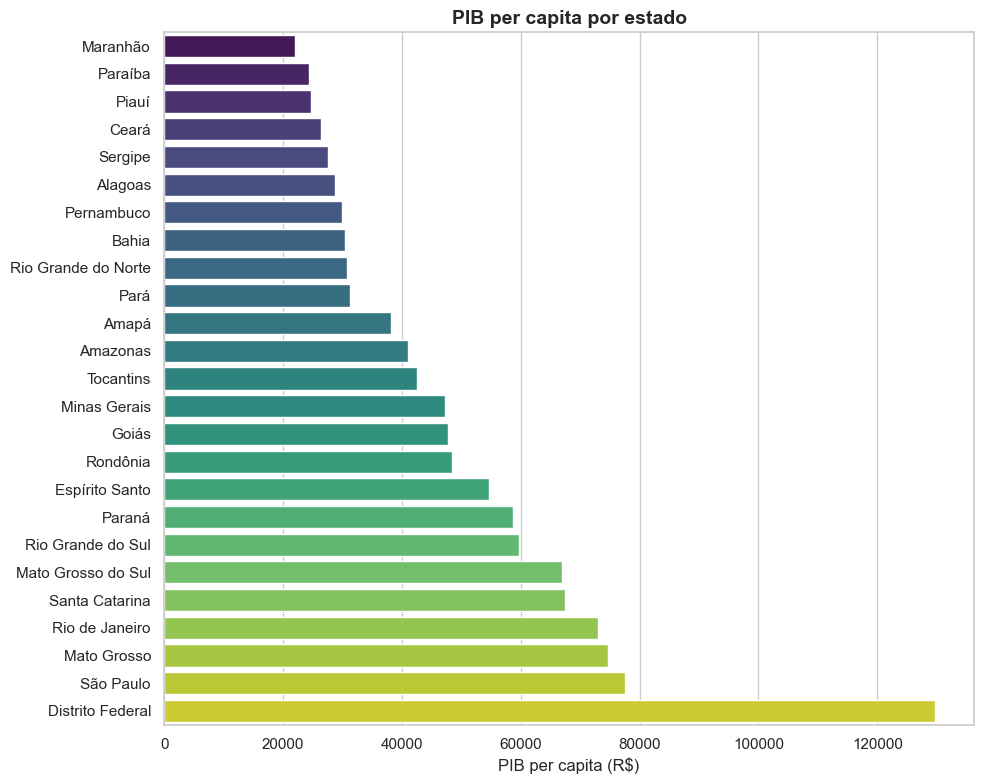

In [367]:
# Gráfico 1 — Contexto: PIB per capita por estado
plt.figure(figsize=(10, 8))
ordenado = base_final.sort_values("pib_per_capita")
sns.barplot(data=ordenado, y="estado", x="pib_per_capita", palette="viridis")
plt.title("PIB per capita por estado", fontsize=14, weight="bold")
plt.xlabel("PIB per capita (R$)")
plt.ylabel("")
plt.tight_layout()
plt.savefig("grafico1_pib_por_estado.png", dpi=150)
plt.show()


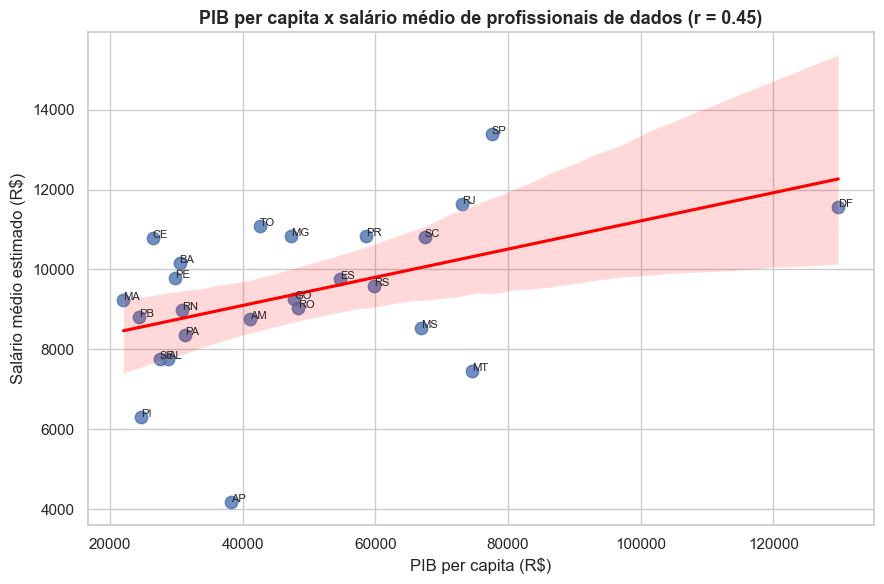

In [368]:
# Gráfico 2 — Evidência central: PIB per capita x salário médio em dados
plt.figure(figsize=(9, 6))
sns.regplot(data=base_final, x="pib_per_capita", y="salario_medio",
            scatter_kws={"s": 80}, line_kws={"color": "red"})
for _, row in base_final.iterrows():
    plt.text(row["pib_per_capita"], row["salario_medio"], row["uf"], fontsize=8)
plt.title(f"PIB per capita x salário médio de profissionais de dados (r = {corr_salario:.2f})",
          fontsize=13, weight="bold")
plt.xlabel("PIB per capita (R$)")
plt.ylabel("Salário médio estimado (R$)")
plt.tight_layout()
plt.savefig("grafico2_pib_x_salario.png", dpi=150)
plt.show()


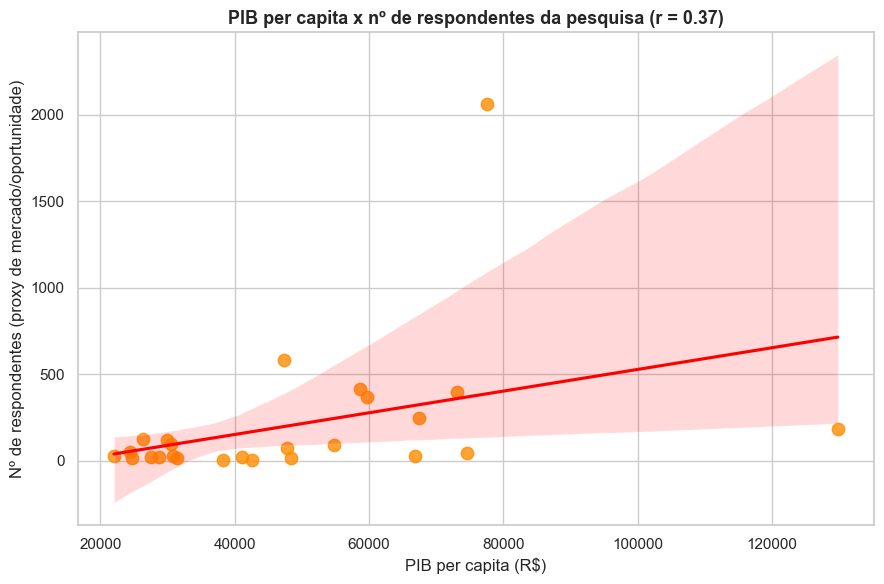

In [369]:
# Gráfico 3 — Oportunidades: PIB per capita x número de respondentes (proxy do tamanho do mercado de dados local)
plt.figure(figsize=(9, 6))
sns.regplot(data=base_final, x="pib_per_capita", y="n_respondentes",
            scatter_kws={"s": 80, "color": "darkorange"}, line_kws={"color": "red"})
plt.title(f"PIB per capita x nº de respondentes da pesquisa (r = {corr_oport:.2f})",
          fontsize=13, weight="bold")
plt.xlabel("PIB per capita (R$)")
plt.ylabel("Nº de respondentes (proxy de mercado/oportunidade)")
plt.tight_layout()
plt.savefig("grafico3_pib_x_oportunidades.png", dpi=150)
plt.show()


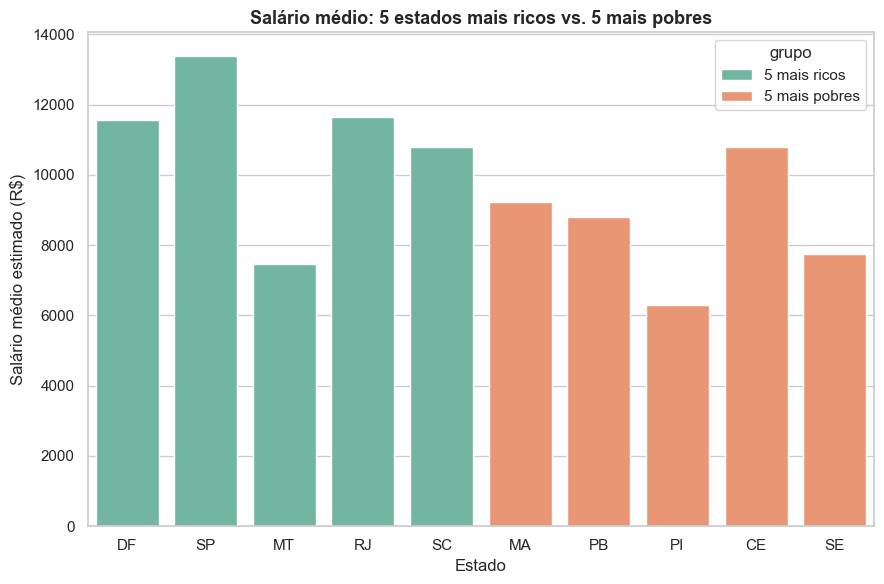

In [370]:
# Gráfico 4 — Contraste: 5 estados mais ricos vs 5 mais pobres
top5 = base_final.nlargest(5, "pib_per_capita").assign(grupo="5 mais ricos")
bottom5 = base_final.nsmallest(5, "pib_per_capita").assign(grupo="5 mais pobres")
comparacao = pd.concat([top5, bottom5])

plt.figure(figsize=(9, 6))
sns.barplot(data=comparacao, x="uf", y="salario_medio", hue="grupo", dodge=False, palette="Set2")
plt.title("Salário médio: 5 estados mais ricos vs. 5 mais pobres", fontsize=13, weight="bold")
plt.xlabel("Estado")
plt.ylabel("Salário médio estimado (R$)")
plt.tight_layout()
plt.savefig("grafico4_top5_vs_bottom5.png", dpi=150)
plt.show()


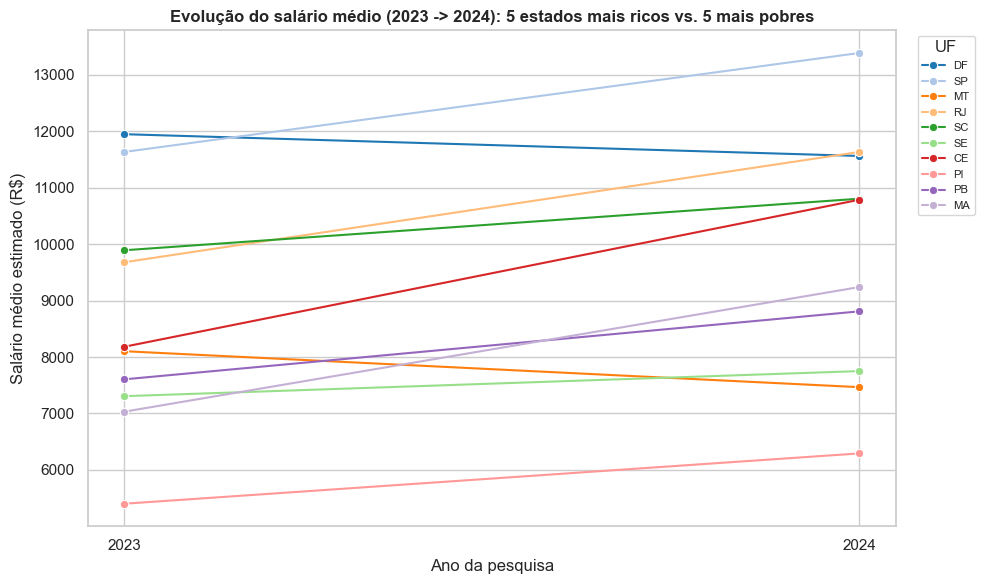

In [371]:
# Gráfico 5 — Evolução 2023 -> 2024: o padrão se sustenta ao longo do tempo?
top5_uf = base_final.nlargest(5, "pib_per_capita")["uf"].tolist()
bottom5_uf = base_final.nsmallest(5, "pib_per_capita")["uf"].tolist()
ufs_destaque = top5_uf + bottom5_uf

subset = base_multi[base_multi["uf"].isin(ufs_destaque)]

plt.figure(figsize=(10, 6))
sns.lineplot(data=subset, x="ano", y="salario_medio", hue="uf", marker="o", palette="tab20")
plt.title("Evolução do salário médio (2023 -> 2024): 5 estados mais ricos vs. 5 mais pobres",
          fontsize=12, weight="bold")
plt.xticks([2023, 2024])
plt.xlabel("Ano da pesquisa")
plt.ylabel("Salário médio estimado (R$)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8, title="UF")
plt.tight_layout()
plt.savefig("grafico5_evolucao_2023_2024.png", dpi=150)
plt.show()


/var/folders/b2/xrf58w4n6c3cxwsj0d7l7wsw0000gn/T/ipykernel_5459/3026935408.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=ordenado_dens, y="estado", x="densidade_profissionais", palette="mako")


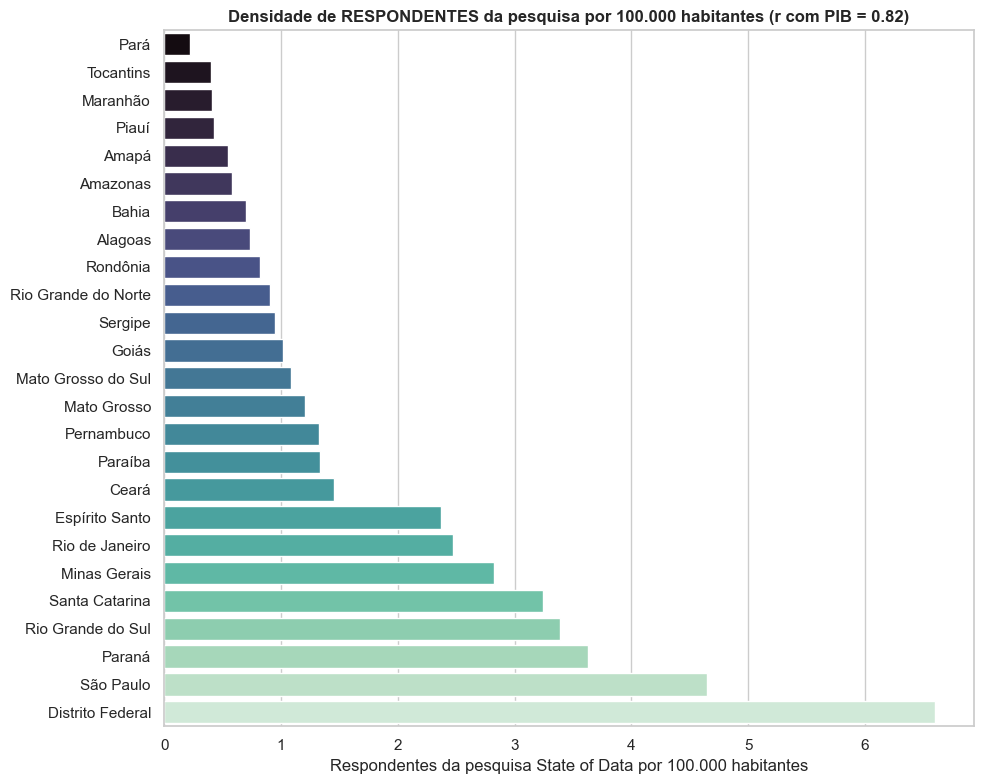

In [372]:
# Gráfico 6 — Densidade de profissionais de dados por 100.000 habitantes
plt.figure(figsize=(10, 8))
ordenado_dens = base_final.sort_values("densidade_profissionais")
sns.barplot(data=ordenado_dens, y="estado", x="densidade_profissionais", palette="mako")
plt.title(f"Densidade de RESPONDENTES da pesquisa por 100.000 habitantes (r com PIB = {corr_densidade:.2f})",
          fontsize=12, weight="bold")
plt.xlabel("Respondentes da pesquisa State of Data por 100.000 habitantes")
plt.ylabel("")
plt.tight_layout()
plt.savefig("grafico6_densidade_profissionais.png", dpi=150)
plt.show()


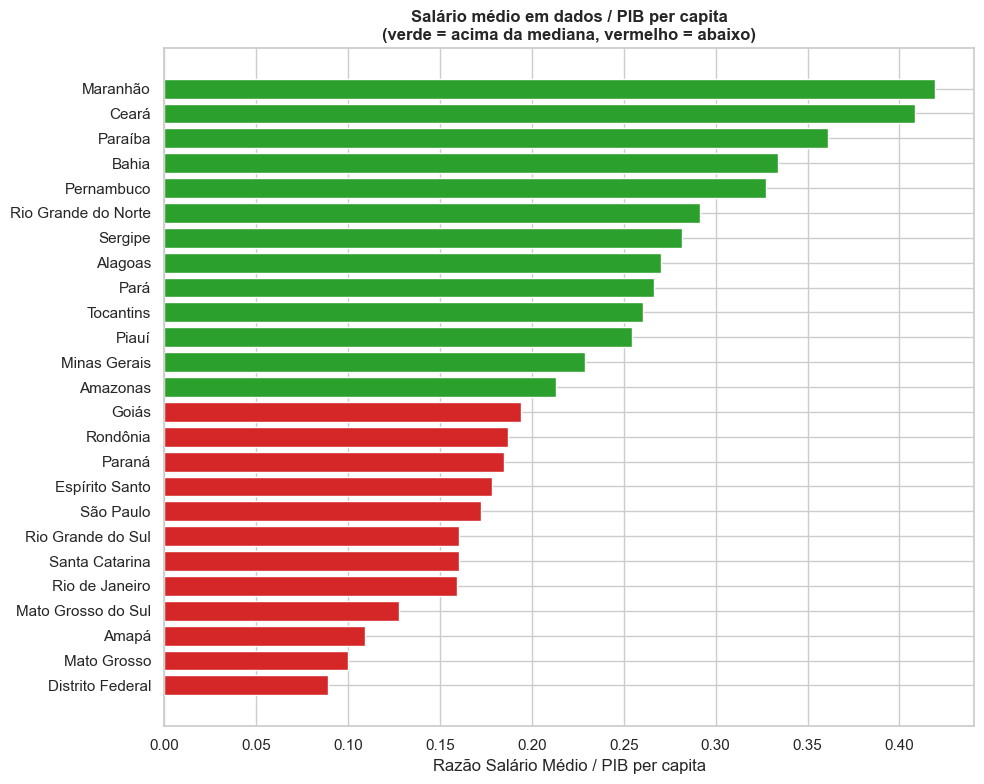

In [373]:
# Gráfico 7 — Salário relativo ao PIB: onde o profissional de dados é mais valorizado localmente
plt.figure(figsize=(10, 8))
ordenado_rel = base_final.sort_values("salario_relativo_pib")
mediana_rel = ordenado_rel["salario_relativo_pib"].median()
cores = ["#d62728" if v < mediana_rel else "#2ca02c" for v in ordenado_rel["salario_relativo_pib"]]

plt.barh(ordenado_rel["estado"], ordenado_rel["salario_relativo_pib"], color=cores)
plt.title("Salário médio em dados / PIB per capita\n(verde = acima da mediana, vermelho = abaixo)",
          fontsize=12, weight="bold")
plt.xlabel("Razão Salário Médio / PIB per capita")
plt.tight_layout()
plt.savefig("grafico7_salario_relativo_pib.png", dpi=150)
plt.show()


In [374]:
print("="*70)
print("RESUMO PARA A CONCLUSÃO")
print("="*70)

print("\n[CORRELAÇÕES — 2024]")
print(f"Pearson  (PIB x salário):      r = {corr_salario:.2f}  (p = {p_salario:.3f})")
print(f"Spearman (PIB x salário):      r = {spearman_salario:.2f}  (p = {p_spearman_salario:.3f})")
print(f"Pearson  sem o DF:              r = {corr_sem_df:.2f}  (p = {p_sem_df:.3f})")
print(f"Pearson  (PIB x respondentes):  r = {corr_oport:.2f}  (p = {p_oport:.3f})")
print(f"Pearson  (PIB x densidade):     r = {corr_densidade:.2f}  (p = {p_densidade:.3f})")

print("\n[REGRESSÃO]")
print(f"R² = {reg.rvalue**2:.3f}  ({reg.rvalue**2*100:.1f}% da variação explicada)")
print(f"IC 95% do r (bootstrap): [{ic_baixo:.2f}, {ic_alto:.2f}]")

print("\n[POOL 2023+2024]")
print(f"n = {len(base_multi)} observações (estado x ano)")
print(f"Pearson pool: r = {corr_pool:.2f}  (p = {p_pool:.3f})")

print("\n[ESTADO MAIS FORA DO PADRÃO — maior resíduo na regressão PIB x salário]")
base_final["residuo"] = base_final["salario_medio"] - (reg.slope * base_final["pib_per_capita"] + reg.intercept)
estado_outlier = base_final.loc[base_final["residuo"].abs().idxmax()]
direcao = "ACIMA" if estado_outlier["residuo"] > 0 else "ABAIXO"
print(f"{estado_outlier['estado']} ({estado_outlier['uf']}): salário R$ {estado_outlier['salario_medio']:.0f}, "
      f"PIB per capita R$ {estado_outlier['pib_per_capita']:.0f} — "
      f"R$ {abs(estado_outlier['residuo']):.0f} {direcao} do esperado pela tendência geral")

print("\n[SALÁRIO RELATIVO AO PIB]")
mais_valorizado = base_final.loc[base_final["salario_relativo_pib"].idxmax()]
menos_valorizado = base_final.loc[base_final["salario_relativo_pib"].idxmin()]
print(f"Mais valorizado: {mais_valorizado['estado']} (razão = {mais_valorizado['salario_relativo_pib']:.3f})")
print(f"Menos valorizado: {menos_valorizado['estado']} (razão = {menos_valorizado['salario_relativo_pib']:.3f})")

print("\n[COBERTURA DA AMOSTRA]")
print(f"Estados com dados em 2024: {len(base_final)} de 27")

RESUMO PARA A CONCLUSÃO

[CORRELAÇÕES — 2024]
Pearson  (PIB x salário):      r = 0.45  (p = 0.023)
Spearman (PIB x salário):      r = 0.45  (p = 0.024)
Pearson  sem o DF:              r = 0.41  (p = 0.045)
Pearson  (PIB x respondentes):  r = 0.37  (p = 0.071)
Pearson  (PIB x densidade):     r = 0.82  (p = 0.000)

[REGRESSÃO]
R² = 0.206  (20.6% da variação explicada)
IC 95% do r (bootstrap): [0.11, 0.70]

[POOL 2023+2024]
n = 50 observações (estado x ano)
Pearson pool: r = 0.57  (p = 0.000)

[ESTADO MAIS FORA DO PADRÃO — maior resíduo na regressão PIB x salário]
Amapá (AP): salário R$ 4167, PIB per capita R$ 38187 — R$ 4866 ABAIXO do esperado pela tendência geral

[SALÁRIO RELATIVO AO PIB]
Mais valorizado: Maranhão (razão = 0.420)
Menos valorizado: Distrito Federal (razão = 0.089)

[COBERTURA DA AMOSTRA]
Estados com dados em 2024: 25 de 27


## 8. Conclusão

### Resposta à pergunta de pesquisa

**Estados mais ricos possuem melhores oportunidades para profissionais de dados?** A resposta, com base nas evidências coletadas, é **sim, parcialmente — e de forma mais sutil do que uma resposta simples de "sim" sugeriria**. Existe uma relação estatisticamente significativa entre riqueza estadual e salário em dados, mas ela é moderada (não determinística), e quando se observa o quanto essa riqueza é *repassada* ao profissional local (salário relativo ao PIB), o padrão se inverte — estados mais pobres chegam a valorizar proporcionalmente mais esse profissional do que os mais ricos.

### Síntese da narrativa visual

A sequência de 7 gráficos construída ao longo do trabalho conta essa história em camadas: o **Gráfico 1** estabeleceu o contexto de riqueza por estado (DF muito acima dos demais, um outlier real); o **Gráfico 2** mostrou a evidência central — a relação positiva entre PIB per capita e salário médio; o **Gráfico 3** tentou medir oportunidades pelo número bruto de respondentes, mas essa métrica não se sustentou estatisticamente; o **Gráfico 4** evidenciou o contraste direto entre os 5 estados mais ricos e mais pobres; o **Gráfico 5** testou se esse padrão se mantinha ao longo do tempo (2023→2024) e confirmou que sim; o **Gráfico 6** corrigiu a falha do Gráfico 3 ao normalizar por população, revelando uma correlação bem mais forte; e o **Gráfico 7** trouxe a virada mais interessante do trabalho — o salário relativo ao PIB, que inverte a intuição inicial.

### Achados estatísticos

A correlação entre PIB per capita e salário médio dos profissionais de dados foi **r = 0,45** (Pearson) e **r = 0,45** (Spearman) — praticamente idênticas, o que indica uma relação **moderada, positiva e bem comportada** (não distorcida por outliers de ranking). Essa relação se manteve mesmo removendo o Distrito Federal (r = 0,41), mostrando que não depende de um único estado extremo, e na verdade **se fortaleceu** ao juntar as edições 2023 e 2024 da pesquisa (n = 50, r = 0,57), reforçando a robustez do achado. A regressão linear mostrou que o PIB per capita explica **20,6%** da variação no salário médio (R²) — uma fração real, mas que deixa claro que a maior parte da variação salarial vem de outros fatores não capturados aqui. O intervalo de confiança via bootstrap [0,11; 0,70] é amplo, refletindo a incerteza natural de uma amostra de ~25 estados.

Já a correlação entre PIB per capita e o número bruto de respondentes foi fraca e **não estatisticamente significativa** (r = 0,37, p = 0,071) — não há evidência suficiente para afirmar que estados mais ricos atraem mais participantes em termos absolutos. Curiosamente, ao normalizar essa mesma métrica pela população (densidade por 100 mil habitantes), a correlação sobe para **r = 0,82** — sugerindo que o tamanho populacional do estado mascarava a relação real.

### A virada: quem valoriza mais o profissional de dados

O salário relativo ao PIB revelou uma inversão notável: o **Maranhão**, um dos estados menos ricos do país, é onde o salário em dados é proporcionalmente **mais valorizado** frente à economia local (razão = 0,420); já o **Distrito Federal**, apesar de pagar os maiores salários em valor absoluto, é onde o profissional é **relativamente menos valorizado** frente à riqueza local (razão = 0,089). Um caso que chama atenção é o **Amapá**, que pagou R$ 4.866 a menos do que sua riqueza local previa pela tendência geral — sugerindo que [sua interpretação: outros fatores como concentração de empresas de tecnologia, trabalho remoto, ou custo de vida também influenciam].

### Trabalhos futuros

Duas tentativas de enriquecer a métrica de "oportunidades" com fontes externas mais precisas (PNAD Contínua via SIDRA, e RAIS via Base dos Dados) não se mostraram viáveis dentro do escopo e prazo deste trabalho — a primeira por agregar profissionais de dados junto com finanças/imóveis/jurídico numa categoria ampla demais, a segunda por fragmentar "profissional de dados" em múltiplos códigos CBO, incluindo um (Cientista de Dados, 2112-20) criado recentemente em março de 2023 e ainda pouco adotado nos registros formais. Um trabalho futuro poderia processar os microdados da PNAD Contínua diretamente (não as tabelas agregadas do SIDRA) para isolar profissionais de TIC com mais precisão, ou usar o Novo CAGED para medir concentração real de vagas/admissões por estado.

**Limitações a mencionar no relatório:**
- A amostra de 2024 cobriu 25 dos 27 estados (sem Roraima e Acre); estados com poucos respondentes geram médias menos confiáveis.
- A correlação entre PIB per capita e número de respondentes brutos **não foi estatisticamente significativa** (p = 0,071 > 0,05) — essa métrica específica deve ser lida com cautela, e só ganha robustez estatística após normalizar por população (densidade).
- PIB per capita mede riqueza agregada, não necessariamente o quanto chega ao setor de tecnologia.
- Faixas salariais foram convertidas pelo ponto médio, o que é uma aproximação.
- No pool 2023+2024, cada estado aparece duas vezes (uma por ano), então as observações não são totalmente independentes — uma limitação estatística a citar.
- Usamos o mesmo PIB per capita (ano-base 2023) para as duas edições da pesquisa, por não haver dado mais recente desagregado por ano disponível.
- A densidade de respondentes é proxy do lado da oferta entre quem já participa da comunidade de dados, não um censo do mercado de trabalho.

## 9. Gerar relatório em PDF (entregável para o professor)

Monta um PDF com capa, introdução, metodologia, métricas avançadas, os 5 gráficos com legenda (a "narrativa visual") e conclusão — pronto para entregar, sem precisar exportar o notebook cru.

In [375]:
%pip install -q fpdf2


You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [376]:
# AJUSTE AQUI: complete só o trecho final entre colchetes com sua interpretação pessoal.
interpretacao_pessoal = (
    "Estados mais ricos possuem melhores oportunidades para profissionais de dados? A resposta, "
    "com base nas evidencias coletadas, e sim, parcialmente -- de forma mais sutil do que um 'sim' "
    "simples sugeriria. Existe uma relacao estatisticamente significativa entre riqueza estadual e "
    "salario em dados (r=0.45, p=0.023), porem moderada, nao deterministica. Essa relacao se manteve "
    "mesmo removendo o Distrito Federal (r=0.41) e se FORTALECEU ao juntar 2023+2024 (n=50, r=0.57). "
    "A regressao mostrou que o PIB per capita explica 20.6% da variacao salarial (R2) -- uma fracao "
    "real, mas que deixa claro que a maior parte da variacao vem de outros fatores.\n\n"
    "A correlacao entre PIB e numero BRUTO de respondentes nao foi estatisticamente significativa "
    "(r=0.37, p=0.071); ja normalizada por populacao (densidade por 100k hab.), sobe para r=0.82, "
    "sugerindo que o tamanho populacional mascarava a relacao real.\n\n"
    "O salario relativo ao PIB revelou uma inversao notavel: o Maranhao, um dos estados menos ricos, "
    "e onde o salario em dados e proporcionalmente MAIS valorizado frente a economia local (razao=0.420); "
    "ja o Distrito Federal, apesar de pagar os maiores salarios absolutos, e onde o profissional e "
    "RELATIVAMENTE MENOS valorizado (razao=0.089). O Amapa pagou R$ 4.866 a menos do que sua riqueza "
    "local previa -- [complete com sua interpretacao: concentracao de empresas de tecnologia, "
    "trabalho remoto, custo de vida]."
)

nome_aluno = "[Seu nome]"
disciplina = "[Nome da disciplina]"
data_entrega = "[Data]"


In [ ]:
from fpdf import FPDF

class RelatorioPDF(FPDF):
    def footer(self):
        self.set_y(-15)
        self.set_font("Helvetica", "I", 8)
        self.set_text_color(120, 120, 120)
        self.cell(0, 10, f"Pagina {self.page_no()}", align="C")

def secao(pdf, titulo, texto):
    pdf.set_font("Helvetica", "B", 16)
    pdf.set_text_color(0, 0, 0)
    pdf.cell(0, 10, titulo, new_x="LMARGIN", new_y="NEXT")
    pdf.ln(2)
    pdf.set_font("Helvetica", "", 11)
    pdf.multi_cell(0, 7, texto)
    pdf.ln(4)

pdf = RelatorioPDF()
pdf.set_auto_page_break(auto=True, margin=20)

# --- Capa ---
pdf.add_page()
pdf.set_y(90)
pdf.set_font("Helvetica", "B", 22)
pdf.multi_cell(0, 12, "Estados mais ricos possuem melhores\noportunidades para profissionais de dados?", align="C")
pdf.ln(8)
pdf.set_font("Helvetica", "", 12)
pdf.multi_cell(0, 8, "Analise comparativa: State of Data Brazil 2023+2024 x PIB per capita por estado", align="C")
pdf.ln(20)
pdf.multi_cell(0, 8, f"{nome_aluno}\n{disciplina}\n{data_entrega}", align="C")

# --- Introducao e metodologia ---
pdf.add_page()
secao(pdf, "1. Introducao", (
    "Este trabalho investiga se estados brasileiros mais ricos oferecem melhores condicoes "
    "para profissionais de dados, cruzando as edicoes 2023 e 2024 da pesquisa State of Data "
    "Brazil (Data Hackers + Bain) com o PIB per capita por estado, coletado via web scraping "
    "da Wikipedia, e aplicando testes estatisticos de robustez."
))
secao(pdf, "2. Metodologia", (
    "Foram utilizadas tres fontes de dados: (1) a base State of Data Brazil, edicoes 2023 e 2024, "
    "com respostas de profissionais de dados sobre estado de residencia e faixa salarial; (2) PIB "
    "per capita por estado (ano-base 2023) e (3) populacao por estado, ambos obtidos via web "
    "scraping de tabelas da Wikipedia. As bases foram integradas pela sigla do estado (UF). A "
    "faixa salarial textual foi convertida para um valor numerico (ponto medio da faixa) para "
    "permitir o calculo de medias e correlacoes."
))
secao(pdf, "3. Metricas Avancadas (robustez)", (
    f"Correlacao de Pearson (2024): r = {corr_salario:.2f} (p = {p_salario:.3f}). "
    f"Correlacao de Spearman (2024): r = {spearman_salario:.2f} (p = {p_spearman_salario:.3f}). "
    f"Correlacao sem o outlier Distrito Federal: r = {corr_sem_df:.2f} (p = {p_sem_df:.3f}). "
    f"Regressao linear: R2 = {reg.rvalue**2:.3f}, explicando {reg.rvalue**2*100:.1f}% da variacao "
    f"no salario medio. Intervalo de confianca (95%) do r via bootstrap: [{ic_baixo:.2f}, {ic_alto:.2f}]. "
    f"Correlacao no pool de 2023+2024 (n={len(base_multi)}): r = {corr_pool:.2f} (p = {p_pool:.3f}). "
    f"Correlacao PIB per capita x densidade de respondentes (por 100k hab.): r = {corr_densidade:.2f} "
    f"(p = {p_densidade:.3f})."
))

# --- Narrativa visual ---
pdf.add_page()
pdf.set_font("Helvetica", "B", 16)
pdf.cell(0, 10, "4. Resultados - Narrativa Visual", new_x="LMARGIN", new_y="NEXT")

graficos = [
    ("grafico1_pib_por_estado.png",
     "Figura 1. Contexto: PIB per capita por estado, do mais pobre ao mais rico."),
    ("grafico2_pib_x_salario.png",
     f"Figura 2. PIB per capita x salario medio de profissionais de dados (r = {corr_salario:.2f}, p = {p_salario:.3f})."),
    ("grafico3_pib_x_oportunidades.png",
     f"Figura 3. PIB per capita x numero de respondentes, proxy de oportunidades (r = {corr_oport:.2f}, p = {p_oport:.3f})."),
    ("grafico4_top5_vs_bottom5.png",
     "Figura 4. Contraste: salario medio nos 5 estados mais ricos vs. os 5 mais pobres."),
    ("grafico5_evolucao_2023_2024.png",
     f"Figura 5. Evolucao do salario medio (2023 -> 2024) nos estados mais ricos e mais pobres. "
     f"Correlacao no pool dos 2 anos: r = {corr_pool:.2f} (p = {p_pool:.3f})."),
    ("grafico6_densidade_profissionais.png",
     f"Figura 6. Densidade de RESPONDENTES da pesquisa por 100.000 habitantes "
     f"(r com PIB per capita = {corr_densidade:.2f})."),
    ("grafico7_salario_relativo_pib.png",
     "Figura 7. Salario medio em dados dividido pelo PIB per capita, por estado — "
     "onde o profissional e mais valorizado em relacao a riqueza local."),
]

for arquivo, legenda in graficos:
    pdf.add_page()
    pdf.image(arquivo, x=15, w=180)
    pdf.ln(5)
    pdf.set_font("Helvetica", "I", 10)
    pdf.set_text_color(80, 80, 80)
    pdf.multi_cell(0, 6, legenda)
    pdf.set_text_color(0, 0, 0)

# --- Conclusao ---
pdf.add_page()
secao(pdf, "5. Conclusao", interpretacao_pessoal)
secao(pdf, "6. Limitacoes", (
    "A amostra de 2024 cobriu 25 dos 27 estados (sem Roraima e Acre); estados com poucos "
    "respondentes geram medias menos confiaveis. A correlacao entre PIB per capita e numero de "
    "respondentes brutos NAO foi estatisticamente significativa (p=0.071 > 0.05) -- essa metrica "
    "deve ser lida com cautela, so ganha robustez apos normalizar por populacao (densidade). PIB "
    "per capita mede riqueza agregada, nao necessariamente o quanto chega ao setor de tecnologia. "
    "Faixas salariais foram convertidas pelo ponto medio, uma aproximacao. No pool 2023+2024, cada "
    "estado aparece duas vezes, entao as observacoes nao sao totalmente independentes. Usamos o "
    "mesmo PIB per capita (ano-base 2023) para as duas edicoes da pesquisa, por nao haver dado mais "
    "recente desagregado por ano disponivel. A densidade de respondentes e proxy do lado da oferta "
    "entre quem ja participa da comunidade de dados, nao um censo do mercado de trabalho (foram "
    "avaliadas e descartadas as alternativas PNAD/SIDRA e RAIS/CBO, ver nota na Secao 6.2)."
))

pdf.output("relatorio_estados_ricos_dados.pdf")
print("PDF gerado: relatorio_estados_ricos_dados.pdf")


FPDFUnicodeEncodingException: Character "—" at index 74 in text is outside the range of characters supported by the font used: "helveticaI". Please consider using a Unicode font.

In [ ]:
from fpdf import FPDF
from datetime import date
from pathlib import Path


def limpar_texto(texto):
    texto = str(texto)

    substituicoes = {
        "—": "-",
        "–": "-",
        "“": '"',
        "”": '"',
        "’": "'",
        "•": "-"
    }

    for antigo, novo in substituicoes.items():
        texto = texto.replace(antigo, novo)

    return texto


class RelatorioPDF(FPDF):
    def footer(self):
        self.set_y(-15)
        self.set_font("Helvetica", "I", 8)
        self.set_text_color(120, 120, 120)
        self.cell(0, 10, f"Página {self.page_no()}", align="C")


def secao(pdf, titulo, texto):
    pdf.set_font("Helvetica", "B", 15)
    pdf.set_text_color(0, 0, 0)
    pdf.multi_cell(0, 8, limpar_texto(titulo))
    pdf.ln(2)

    pdf.set_font("Helvetica", "", 11)
    pdf.set_text_color(40, 40, 40)
    pdf.multi_cell(0, 7, limpar_texto(texto))
    pdf.ln(5)


pdf = RelatorioPDF()
pdf.set_auto_page_break(auto=True, margin=20)


# ============================================================
# CAPA
# ============================================================

pdf.add_page()

pdf.set_y(35)
pdf.set_font("Helvetica", "B", 14)
pdf.cell(
    0,
    8,
    limpar_texto("CEUB - Centro Universitário de Brasília"),
    align="C",
    new_x="LMARGIN",
    new_y="NEXT"
)

pdf.set_font("Helvetica", "", 12)
pdf.cell(
    0,
    8,
    align="C",
    new_x="LMARGIN",
    new_y="NEXT"
)

pdf.cell(
    0,
    8,
    limpar_texto("Disciplina: Ciência de Dados"),
    align="C",
    new_x="LMARGIN",
    new_y="NEXT"
)

pdf.set_y(105)
pdf.set_font("Helvetica", "B", 21)
pdf.multi_cell(
    0,
    10,
    limpar_texto("Estados mais ricos possuem melhores oportunidades para profissionais de dados?"),
    align="C"
)

pdf.ln(8)
pdf.set_font("Helvetica", "", 12)
pdf.multi_cell(
    0,
    8,
    limpar_texto(
        "Análise comparativa entre State of Data Brazil 2023 e 2024 "
        "e indicadores econômicos estaduais"
    ),
    align="C"
)

pdf.set_y(190)
pdf.set_font("Helvetica", "B", 12)
pdf.cell(
    0,
    8,
    limpar_texto("Identificação do grupo"),
    align="C",
    new_x="LMARGIN",
    new_y="NEXT"
)

pdf.set_font("Helvetica", "", 12)
pdf.cell(
    0,
    8,
    limpar_texto("Integrantes: Mateus Cavalcante e Vitor Reis"),
    align="C",
    new_x="LMARGIN",
    new_y="NEXT"
)

pdf.cell(
    0,
    8,
    limpar_texto("Professor: Weslley Rodrigues"),
    align="C",
    new_x="LMARGIN",
    new_y="NEXT"
)

pdf.set_y(260)
pdf.set_font("Helvetica", "", 11)
pdf.cell(
    0,
    8,
    limpar_texto(f"Brasília - DF, {date.today().strftime('%d/%m/%Y')}"),
    align="C"
)


# ============================================================
# RELATÓRIO
# ============================================================

pdf.add_page()

secao(pdf, "1. Pergunta de Pesquisa e Objetivo Analítico", """
A pergunta de pesquisa deste trabalho é: estados brasileiros economicamente mais ricos oferecem melhores oportunidades para profissionais da área de dados?

O objetivo é analisar se existe relação entre o PIB per capita dos estados brasileiros e indicadores do mercado de dados, como salário médio, quantidade de respondentes da pesquisa e densidade de profissionais por população.
""")

secao(pdf, "2. Descrição das Bases de Dados Utilizadas", """
A primeira base utilizada foi a State of Data Brazil, nas edições de 2023 e 2024. Essa base contém respostas de profissionais da área de dados sobre localização, faixa salarial, perfil profissional e outras características do mercado de trabalho.

A segunda base utilizada foi uma base externa contendo informações de PIB per capita e população dos estados brasileiros. Esses dados foram usados para representar a riqueza econômica dos estados e permitir a comparação com os indicadores profissionais.
""")

secao(pdf, "3. Procedimentos de Coleta dos Dados", """
Os dados da State of Data Brazil foram obtidos em arquivos CSV e consolidados em uma base única para análise. Já os dados externos de PIB per capita e população foram coletados por meio de web scraping de tabelas públicas disponíveis na internet.

Depois da coleta, os dados foram carregados no Python para tratamento, integração, análise estatística e geração dos gráficos.
""")

secao(pdf, "4. Limpeza, Transformação e Integração dos Dados", """
O processo de limpeza envolveu a padronização das siglas dos estados, o tratamento de valores ausentes e a conversão das faixas salariais em valores numéricos aproximados.

Como a pesquisa apresenta salários em faixas, foi utilizado o ponto médio de cada faixa para permitir o cálculo de médias, correlações e comparações entre estados.

A integração das bases foi feita usando a sigla da unidade federativa, UF, como chave de junção entre os dados da pesquisa e os dados econômicos.
""")

secao(pdf, "5. Modelo de Recuperação da Informação Utilizado", """
O trabalho utilizou uma abordagem baseada no Modelo Vetorial de Recuperação da Informação, pois os estados foram representados por vetores de atributos numéricos, como PIB per capita, salário médio, quantidade de respondentes e densidade de profissionais.

Essa escolha permitiu comparar os estados entre si e analisar relações entre variáveis econômicas e profissionais. Também foram utilizadas métricas estatísticas, como correlação de Pearson, correlação de Spearman, regressão linear e análises de robustez.
""")

secao(pdf, "6. Principais Métricas Estatísticas", f"""
As principais métricas encontradas foram:

- Correlação de Pearson entre PIB per capita e salário médio em 2024: r = {corr_salario:.2f}, p = {p_salario:.3f}.
- Correlação de Spearman: r = {spearman_salario:.2f}, p = {p_spearman_salario:.3f}.
- Correlação sem o Distrito Federal: r = {corr_sem_df:.2f}, p = {p_sem_df:.3f}.
- Regressão linear: R² = {reg.rvalue**2:.3f}, indicando que aproximadamente {reg.rvalue**2 * 100:.1f}% da variação do salário médio pode ser explicada pelo PIB per capita.
- Correlação no conjunto agregado de 2023 e 2024: r = {corr_pool:.2f}, p = {p_pool:.3f}.
- Correlação entre PIB per capita e densidade de respondentes: r = {corr_densidade:.2f}, p = {p_densidade:.3f}.
""")

secao(pdf, "7. Visualizações e Análise dos Resultados", """
Os gráficos produzidos mostram a distribuição do PIB per capita por estado, a relação entre PIB per capita e salário médio, a relação entre PIB per capita e quantidade de respondentes, a comparação entre estados mais ricos e mais pobres, a evolução dos salários entre 2023 e 2024, a densidade de profissionais e o salário relativo ao PIB per capita.

De forma geral, os resultados indicam que estados mais ricos tendem a apresentar melhores salários médios e maior concentração de profissionais de dados. No entanto, essa relação não é perfeita, mostrando que outros fatores também influenciam o mercado de trabalho, como trabalho remoto, concentração de empresas, nível de qualificação e dinâmica econômica regional.
""")


# ============================================================
# ANÁLISE DOS GRÁFICOS
# ============================================================

secao(pdf, "8. Análise dos Gráficos", """
Nesta seção são apresentados os principais gráficos gerados a partir da integração entre os dados da pesquisa State of Data Brazil e os indicadores econômicos dos estados brasileiros.

As visualizações permitem analisar a relação entre desenvolvimento econômico, remuneração, concentração de profissionais e oportunidades no mercado de trabalho da área de dados.

As análises realizadas buscam responder à pergunta central deste estudo: estados economicamente mais ricos oferecem melhores oportunidades para profissionais da área de dados?
""")

graficos = [
    (
        "grafico1_pib_por_estado.png",
        "Figura 1. PIB per capita por estado brasileiro. Observa-se uma expressiva estatística econômica entre as unidades federativas, com destaque para estados das regiões Sudeste e Centro-Oeste, que apresentam níveis de riqueza superiores aos das regiões Norte e Nordeste. Essa desigualdade regional constitui um importante fator de contexto para compreender diferenças salariais e de oportunidades no mercado de trabalho para profissionais de dados."
    ),

    (
        "grafico2_pib_x_salario.png",
        f"Figura 2. Relação entre PIB per capita estadual e salário médio dos profissionais de dados. O gráfico evidencia uma associação positiva moderada entre as variáveis, indicando que estados economicamente mais desenvolvidos tendem a oferecer maiores remunerações. O coeficiente de correlação de Pearson (r = {corr_salario:.2f}) sugere que, embora a riqueza regional influencie os salários, outros fatores, como demanda local, nível de especialização e presença de empresas de tecnologia, também exercem papel relevante."
    ),

    (
        "grafico3_pib_x_oportunidades.png",
        f"Figura 3. Relação entre PIB per capita e número de respondentes por estado, utilizado como proxy para concentração de profissionais e oportunidades de emprego. Verifica-se que estados com maior nível de desenvolvimento econômico tendem a concentrar um número mais elevado de profissionais da área de dados. A correlação obtida (r = {corr_oport:.2f}) reforça a hipótese de que regiões mais ricas atraem e retêm maior capital humano especializado."
    ),

    (
        "grafico4_top5_vs_bottom5.png",
        "Figura 4. Comparação entre os cinco estados com maior PIB per capita e os cinco estados com menor PIB per capita. Nota-se que os estados mais ricos apresentam, em média, salários superiores aos observados nos estados menos desenvolvidos economicamente. Entretanto, a existência de variações dentro dos próprios grupos indica que o nível de desenvolvimento econômico não é o único determinante da remuneração dos profissionais de dados."
    ),

    (
        "grafico5_evolucao_2023_2024.png",
        f"Figura 5. Evolução do salário médio dos profissionais de dados entre os anos de 2023 e 2024. A análise evidencia mudanças na distribuição salarial ao longo do período, possivelmente associadas ao amadurecimento do mercado, ao aumento da demanda por especialistas e às transformações econômicas recentes. A correlação considerando o conjunto agregado dos dois anos (r = {corr_pool:.2f}) indica que a relação entre riqueza regional e remuneração permanece consistente ao longo do tempo."
    ),

    (
        "grafico6_densidade_profissionais.png",
        f"Figura 6. Densidade de profissionais de dados por 100 mil habitantes. Os resultados demonstram que estados com maior PIB per capita tendem a apresentar maior concentração de profissionais especializados. A forte correlação observada (r = {corr_densidade:.2f}) sugere que o desenvolvimento econômico regional favorece a formação de ecossistemas tecnológicos e a atração de mão de obra qualificada."
    ),

    (
        "grafico7_salario_relativo_pib.png",
        "Figura 7. Salário médio relativo ao PIB per capita estadual. Essa métrica permite avaliar a valorização do profissional de dados em relação ao nível de riqueza local. Observa-se que alguns estados apresentam salários proporcionalmente elevados mesmo possuindo menor PIB per capita, indicando possíveis nichos de mercado ou escassez de profissionais especializados. Dessa forma, a remuneração relativa pode revelar oportunidades atrativas fora dos principais polos econômicos do país."
    )
]

for arquivo, legenda in graficos:
    if Path(arquivo).exists():

        pdf.add_page()

        pdf.image(arquivo, x=15, w=180)

        pdf.ln(6)

        pdf.set_font("Helvetica", "I", 10)
        pdf.set_text_color(80, 80, 80)

        pdf.multi_cell(
            0,
            6,
            limpar_texto(legenda)
        )

        pdf.set_text_color(0, 0, 0)


# ============================================================
# CONCLUSÕES, LIMITAÇÕES E REFERÊNCIAS
# ============================================================

pdf.add_page()

secao(pdf, "9. Conclusões", """
Com base nas análises realizadas, conclui-se que existe uma tendência de estados mais ricos apresentarem melhores condições para profissionais da área de dados, especialmente em relação ao salário médio e à concentração de profissionais.

No entanto, a relação não é absoluta. O PIB per capita ajuda a explicar parte das diferenças, mas não explica sozinho todo o comportamento do mercado. Outros fatores, como presença de empresas de tecnologia, trabalho remoto, custo de vida, nível de qualificação e concentração de oportunidades, também influenciam os resultados.

Assim, os resultados apontam que a riqueza econômica estadual está associada a melhores oportunidades, mas deve ser analisada em conjunto com outros indicadores sociais, econômicos e profissionais.
""")

secao(pdf, "10. Limitações do Estudo", """
A principal limitação está no fato de a State of Data Brazil ser uma pesquisa baseada em respostas voluntárias, o que pode gerar vieses de representatividade.

Outra limitação é que alguns estados possuem poucos respondentes, tornando as médias salariais menos confiáveis. Além disso, o PIB per capita representa a riqueza média do estado, mas não necessariamente a realidade específica do setor de tecnologia.

Também houve a necessidade de transformar faixas salariais em valores numéricos aproximados, o que pode gerar pequenas distorções nos cálculos. Por fim, a quantidade de respondentes foi usada como proxy de oportunidades, mas não representa diretamente o número real de vagas disponíveis.
""")

secao(pdf, "11. Referências", """
DATA HACKERS; BAIN & COMPANY. State of Data Brazil 2023 e 2024.

INSTITUTO BRASILEIRO DE GEOGRAFIA E ESTATÍSTICA. Indicadores econômicos e demográficos dos estados brasileiros.

WIKIPEDIA. Produto Interno Bruto per capita das unidades federativas do Brasil.

PYTHON SOFTWARE FOUNDATION. Documentação das bibliotecas Python utilizadas: pandas, matplotlib, seaborn, scipy e fpdf.
""")


# ============================================================
# EXPORTAÇÃO DO PDF
# ============================================================

pdf.output("relatorio_estados_ricos_dados.pdf")
print("PDF gerado: relatorio_estados_ricos_dados.pdf")

PDF gerado: relatorio_estados_ricos_dados.pdf
